In [6]:
def execute_heatmap(source_df, df_equipments, aggregate: str, start_date: str, end_date: str, min_value: float,
    max_value: float, sort_first_column: bool = False, display_fig: bool = True
) -> None:
    """Generate clustered heatmaps for equipment sensor data within a date range.
    
    Processes Spark DataFrames, filters data, converts to pandas for visualization,
    and generates annotated heatmaps with optional clustering/sorting.
    
    Parameters:
        source_df (DataFrame): Spark DataFrame containing raw sensor data
        df_equipments (DataFrame): Spark DataFrame with equipment metadata
        aggregate (str): Aggregation type for visualization title
        start_date (str): Start date in 'YYYY-MM-DD HH:MM:SS' format
        end_date (str): End date in 'YYYY-MM-DD HH:MM:SS' format
        min_value (float): Minimum valid sensor value for filtering
        max_value (float): Maximum valid sensor value for filtering
        sort_first_column (bool): Sort by first column instead of clustering
    """
    figures = []
    # Convert aggregation type for display purposes
    aggregate = convert_aggregate(aggregate)
    
    # Generate timestamp for unique filenames
    timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    
    # Convert string dates to datetime objects
    start_date_dt = datetime.strptime(start_date, "%Y-%m-%d %H:%M:%S")
    end_date_dt = datetime.strptime(end_date, "%Y-%m-%d %H:%M:%S")

    brake_temp_tags = [
        "Lt Front Brake Temperature",
        "Lt Rear Brake Temperature",
        "Rt Front Brake Temperature",
        "Rt Rear Brake Temperature"
    ]

    # Process each equipment group
    for index, row_equipment in df_equipments.iterrows():
        equipment_name = row_equipment["Equipment"]
        class_type = row_equipment["ClassType"]
        print(f"Processing: {class_type} | {equipment_name}")

        # 1. Filter Payload (180-280)
        df_payload = source_df.filter(
            (col("Nombre_Camion").isin(equipment_name)) &
            (col("Nombre_Tag") == "Payload") &
            (col("Fecha_Hora").between(lit(start_date_dt), lit(end_date_dt))) &
            (col("Valor").between(180, 280))
        )

        # 2. Filter Brake Temps (1-130)
        brake_temp_tags = [
            "Lt Front Brake Temperature",
            "Lt Rear Brake Temperature",
            "Rt Front Brake Temperature",
            "Rt Rear Brake Temperature"
        ]
        df_brake_temps = source_df.filter(
            (col("Nombre_Camion").isin(equipment_name)) &
            (col("Nombre_Tag").isin(brake_temp_tags)) &
            (col("Fecha_Hora").between(lit(start_date_dt), lit(end_date_dt))) &
            (col("Valor").between(1, 130))
        )

        # 3. Filter Engine Cool & Boost Pressure (1-200)
        df_engine_boost = source_df.filter(
            (col("Nombre_Camion").isin(equipment_name)) &
            (col("Nombre_Tag").isin(["Engine Cool Temperature", "Boost Pressure"])) &
            (col("Fecha_Hora").between(lit(start_date_dt), lit(end_date_dt))) &
            (col("Valor").between(1, 130))
        )

        # 4. Union all DataFrames (no duplicates expected if source is clean)
        df_filtered = df_payload.union(df_brake_temps).union(df_engine_boost)
        pandas_df = df_filtered.toPandas()

        # Create analysis dataset
        if not pandas_df.empty:
            dataset = pandas_df[["Nombre_Camion", "Nombre_Tag", "Valor"]]
            dataset.columns = ["Equipment", "Sensor", "Value"]
            print(f"Data points after filtering: {len(dataset)}")

            if not dataset.empty:
                # Create pivot table of mean values
                pivot_df = dataset.pivot_table(
                    index="Equipment",
                    columns="Sensor",
                    values="Value",
                    aggfunc="mean"
                )
                
                # Handle missing values after pivoting
                pivot_df.fillna(0, inplace=True)
                
                # Sorting logic
                cluster_on = True
                if sort_first_column:
                    pivot_df = pivot_df.sort_values(by=pivot_df.columns[0], ascending=True)
                    cluster_on = False

                # Only plot if multiple equipment entries exist
                if len(pivot_df) > 1:
                    plt.figure(figsize=(40, 32))
                    
                    # Create clustered heatmap
                    grid = sns.clustermap(
                        pivot_df,
                        annot=True,
                        cmap='viridis_r',
                        fmt=".2f",
                        row_cluster=cluster_on,
                        col_cluster=cluster_on
                    )
                    
                    # Configure plot aesthetics
                    plt.suptitle(
                        f'Sensor Heatmap "{aggregate} frequency" | {class_type} ({start_date_dt.date()} - {end_date_dt.date()})',
                        fontsize=14,
                        fontweight="bold",
                        x=0.85,
                        y=0.98
                    )
                    grid.ax_heatmap.set_xlabel("Sensor Features")
                    grid.ax_heatmap.set_ylabel("Equipment Units")
                    grid.fig.axes[2].invert_yaxis()

                    # Save before showing to prevent blank image
                    save_path = f"/lakehouse/default/Files/Images/Heatmap_Analysis/Heatmap_{class_type}_{aggregate}_({start_date_dt.date()}-{end_date_dt.date()})_{timestamp}.jpeg"
                    grid.savefig(save_path, dpi=400, bbox_inches='tight')
                    figures.append(grid.fig)
                    print(f"Heatmap saved to: {save_path}")
                    
                    if display_fig:
                        plt.show()
            
        else:
            print("No data found for current equipment")

    pdf_filename = f'/lakehouse/default/Files/PDF/Heatmap_Analysis/Heatmap_{aggregate}_({start_date_dt.date()}-{end_date_dt.date()})_{timestamp}.pdf'
    with PdfPages(pdf_filename) as pdf:
        for fig in figures:
            pdf.savefig(fig, bbox_inches='tight', dpi=400)
        print(f'PDF Saved to: {pdf_filename}')
    
    for fig in figures:
        plt.close(fig)

StatementMeta(, f5cb62c6-e271-4971-8e31-30541c6b5e15, 8, Finished, Available, Finished)

# Call data from source

In [7]:
source_df = spark.table("sensores_camiones")
source_df = source_df.withColumn("Fecha_Hora", to_timestamp(col("Fecha_Hora"), "yyyy-MM-dd HH:mm:ss"))
source_df = source_df.withColumn("Valor", col("Valor").cast("double"))

df_payload_filtered = source_df.filter(
    (col("Nombre_Tag") == "Payload")
)

pandas_df = df_payload_filtered.toPandas()

min_payload = pandas_df["Valor"].min()
max_payload = pandas_df["Valor"].max()

print(f"Min Payload: {min_payload}")
print(f"Max Payload: {max_payload}")

StatementMeta(, f5cb62c6-e271-4971-8e31-30541c6b5e15, 9, Finished, Available, Finished)

Min Payload: 0.0
Max Payload: 300.0


# Heatmap with hourly, daily, weekly and monthly data from January 2024 to Now | between 1 - 130

In [8]:
min_value = 1
max_value = 130

# Apply filtering: Only keep non-null values in 'Valor' that are between Min and Max Value
filtered_df = source_df.filter((col("Valor").isNotNull()))

StatementMeta(, f5cb62c6-e271-4971-8e31-30541c6b5e15, 10, Finished, Available, Finished)

### Hourly December 2024

StatementMeta(, f5cb62c6-e271-4971-8e31-30541c6b5e15, 11, Finished, Available, Finished)

Processing: Cat 793C | ['TRH380', 'TRH374', 'TRH376', 'TRH377', 'TRH378', 'TRH379', 'TRH382', 'TRH385', 'TRH386', 'TRH390', 'TRH391', 'TRH392', 'TRH394', 'TRH395', 'TRH396', 'TRH398', 'TRH340', 'TRH370', 'TRH371', 'TRH372', 'TRH373', 'TRH375', 'TRH381', 'TRH383', 'TRH384', 'TRH387', 'TRH388', 'TRH389', 'TRH393', 'TRH399']
Data points after filtering: 419696
Heatmap saved to: /lakehouse/default/Files/Images/Heatmap_Analysis/Heatmap_Cat 793C_Hourly_(2024-12-01-2025-04-04)_2025-04-04_16-07-37.jpeg


<Figure size 4000x3200 with 0 Axes>

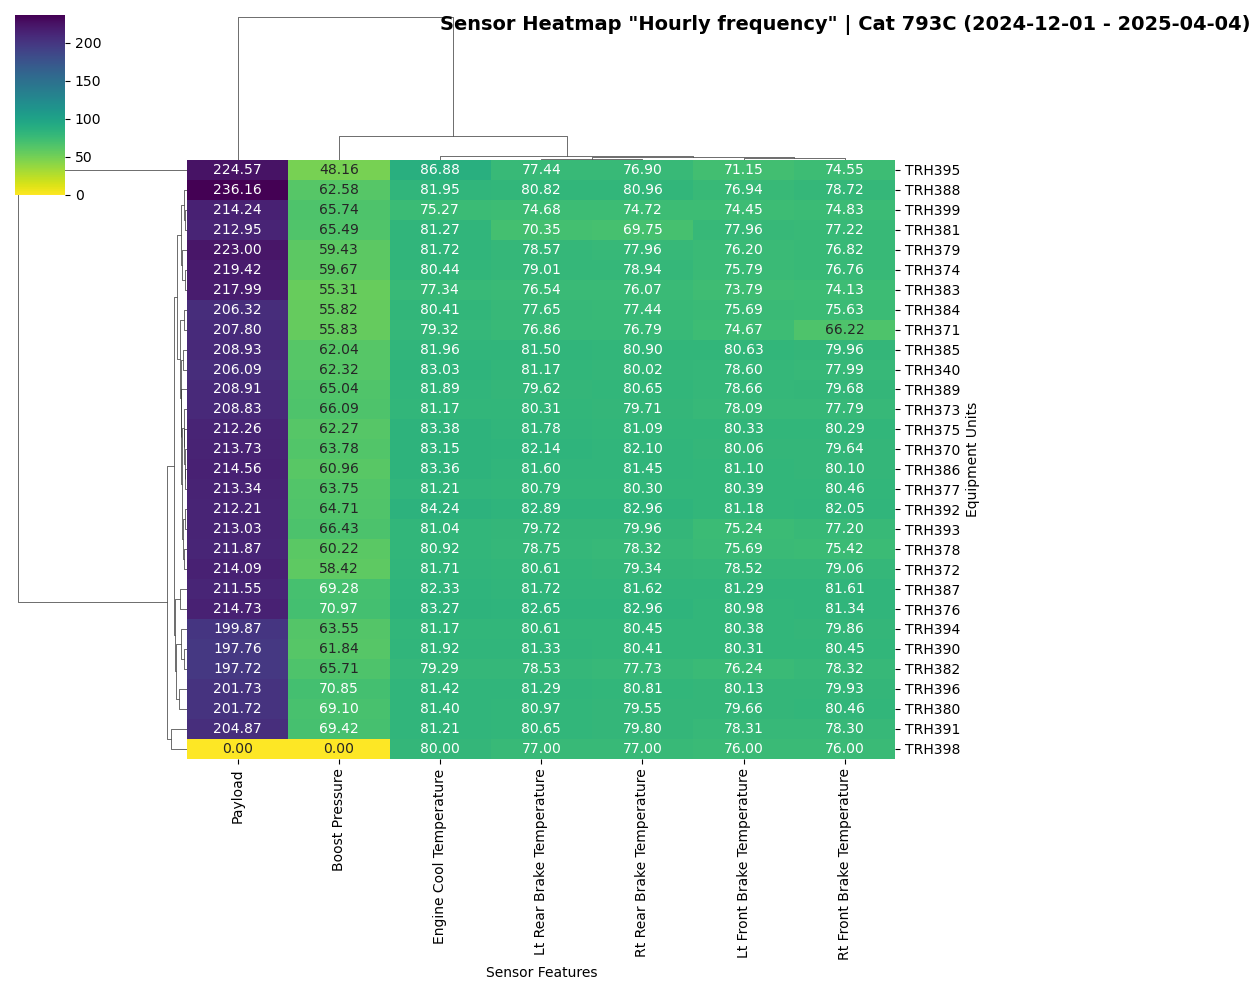

Processing: Cat 793D | ['TRH342', 'TRH343', 'TRH361', 'TRH362', 'TRH363', 'TRH364', 'TRH344', 'TRH345', 'TRH346', 'TRH359', 'TRH360', 'TRH365', 'TRH366', 'TRH367', 'TRH368', 'TRH369', 'TRH347']
Data points after filtering: 240226
Heatmap saved to: /lakehouse/default/Files/Images/Heatmap_Analysis/Heatmap_Cat 793D_Hourly_(2024-12-01-2025-04-04)_2025-04-04_16-07-37.jpeg


<Figure size 4000x3200 with 0 Axes>

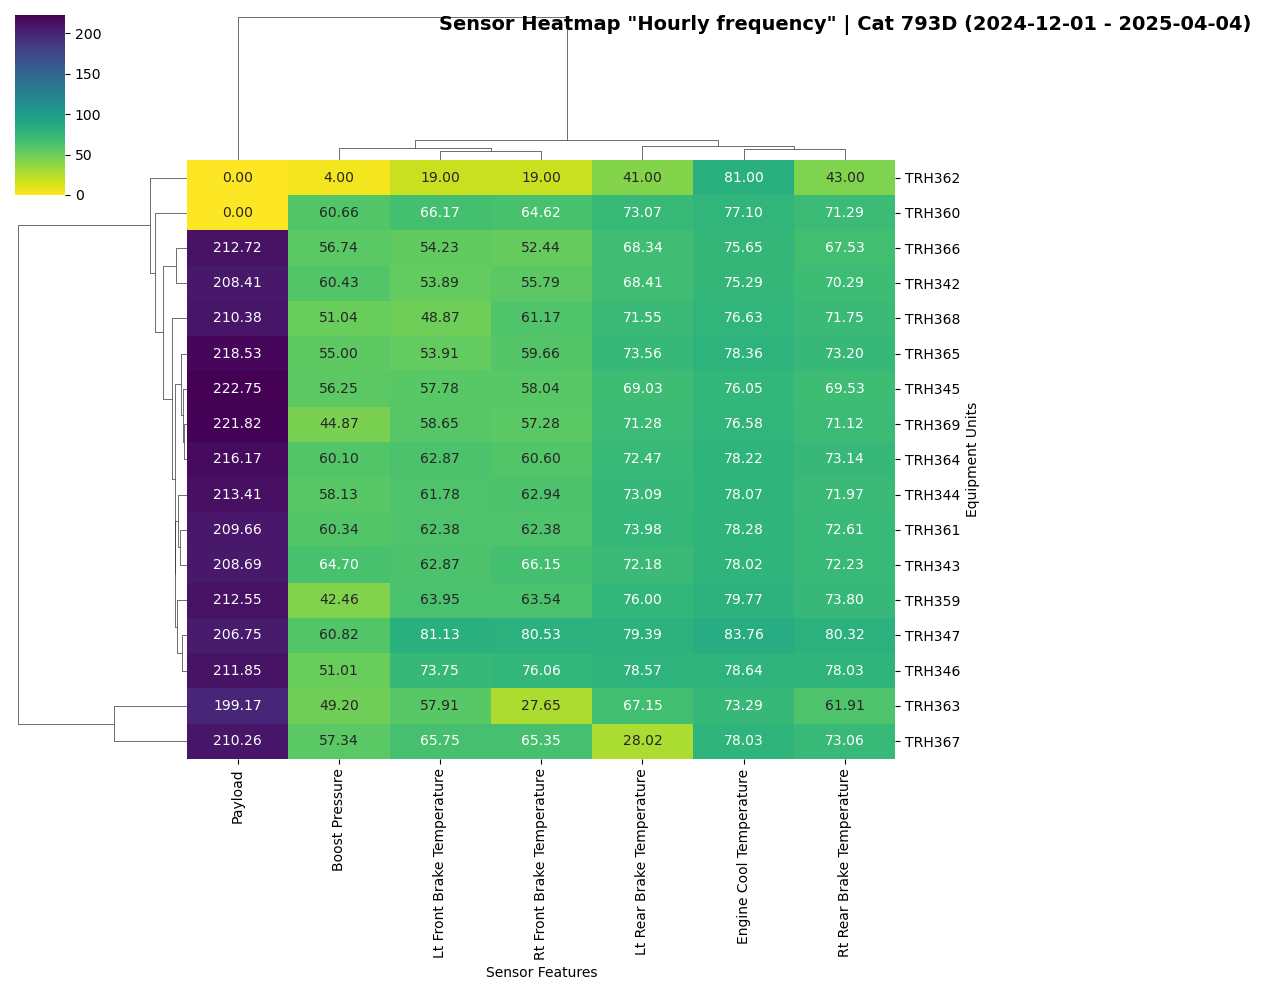

PDF Saved to: /lakehouse/default/Files/PDF/Heatmap_Analysis/Heatmap_Hourly_(2024-12-01-2025-04-04)_2025-04-04_16-07-37.pdf


In [9]:
""" Example:
minute_source_df = aggregate_data(source_df, "minute") # Original data
hour_source_df = aggregate_data(source_df, "hour")
day_source_df = aggregate_data(source_df, "day")
week_source_df = aggregate_data(source_df, "week")
month_source_df = aggregate_data(source_df, "month")
"""
start_date = "2024-12-01 00:00:00"
aggregate = "hour"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
aggregate_source_df = aggregate_data(filtered_df, aggregate)
execute_heatmap(
    source_df=aggregate_source_df,
    df_equipments=df_equipments, 
    aggregate=aggregate,
    start_date=start_date, 
    end_date=end_date,
    min_value=min_value,
    max_value=max_value,
    sort_first_column=False
)